# Home, work and commuting in Munich from one month of Locomizer signals

*One notebook per city: the city is chosen with `CITY_KEY` in the parameter cell.*

Input: the monthly user–day–cell table built by `userday_month.ipynb` (one row per user, day and H3 level-8 cell, with the
number of signals per hour). Output: a home cell and a work cell per user, how many days support each, and the commuting
patterns for the Munich city and metropolitan area.

## Method (citable)

Home and work are the **most frequent location in a time window over the whole month**, the rule implemented by the
`home_location` function of scikit-mobility (Pappalardo, Simini, Barlacchi & Pellungrini, 2022, *scikit-mobility: A Python library
for the analysis, generation, and risk assessment of mobility data*, Journal of Statistical Software 103(4)) and used for home and
work by Alexander, Jiang, Murga & González (2015, *Origin–destination trips by purpose and time of day inferred from mobile phone
data*, Transportation Research Part C 58, 240–250):

- **Home** = the cell with the most signals during **night hours** (default 22:00–07:00, the scikit-mobility default) over the month.
- **Work** = the cell **other than home** with the most signals during **working hours on working days** (default 09:00–17:00,
  Monday–Friday, public holidays of the city's federal state excluded) over the month. Signals at the home cell are simply ignored when looking for
  work, so someone who spends much of the day at home still gets a work cell if they are regularly somewhere else.
- **Support**: `home_days` is the number of nights with at least one signal at the home cell, `work_days` the number of working
  days with at least one working-hour signal at the work cell. Following Alexander et al. (2015) and Vanhoof, Reis, Ploetz & Smoreda
  (2018, *Assessing the quality of home detection from mobile phone data for official statistics*, Journal of Official Statistics
  34(4), 935–960), who show that the observation window and the minimum number of observed days change the results materially,
  a user is kept only with `home_days >= H_MIN` and `work_days >= W_MIN`, and several (H, W) pairs are compared.

Cells are **H3 level 8** (about 0.74 km²), so small GPS jitter does not split a home or workplace over neighbouring cells.

**Boundaries** come from the Eurostat / GISCO *Urban Audit 2021* layers (downloaded automatically on first run):
the **city** is the Urban Audit city (the municipality, code `CITY_CODE`) and the **metro** is its
**Functional Urban Area** (code `FUA_CODE`): the city plus its commuting zone as defined by the EU/OECD method, which is the
natural unit for a commuting analysis. In the code and tables `metro` always means this FUA, and `metro_other` the commuting zone
outside the city.

## Parameters to play with

`NIGHT_HOURS`, `WORK_HOURS`, `HOLIDAYS`, and the list of (`home_days`, `work_days`) thresholds to compare. The selected pair
`H_MIN, W_MIN` is used for the Munich analysis (default 10 nights, 4 working days).

**Resources**: run in Jupyter at <https://www.roihu.csc.fi> with 8 cores and 32 GB; the passes over the monthly table take a few minutes.

In [1]:
import os, json, urllib.request
from pathlib import Path
import duckdb, h3, geopandas as gpd, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from shapely.geometry import Polygon

# ---- parameters -------------------------------------------------------------
COUNTRY = "DEU"
MONTH   = "2024-05"
H3_RES  = 8

# ---- which city: Eurostat Urban Audit codes (city, FUA) and the public holidays of its federal state in {MONTH} (day of month) ----
CITIES = {
    "munich":    dict(name="Munich",    city="DE003C", fua="DE003F", holidays=[1, 9, 20, 30]),   # Bavaria: Labour Day, Ascension, Whit Monday, Corpus Christi
    "berlin":    dict(name="Berlin",    city="DE001C", fua="DE001F", holidays=[1, 9, 20]),       # Berlin
    "hamburg":   dict(name="Hamburg",   city="DE002C", fua="DE002F", holidays=[1, 9, 20]),       # Hamburg
    "frankfurt": dict(name="Frankfurt", city="DE005C", fua="DE005F", holidays=[1, 9, 20, 30]),   # Hesse
    "cologne":   dict(name="Cologne",   city="DE004C", fua="DE004F", holidays=[1, 9, 20, 30]),   # North Rhine-Westphalia
}
CITY_KEY = "munich"
CITY_NAME, CITY_CODE, FUA_CODE, HOLIDAYS = (CITIES[CITY_KEY][k] for k in ("name", "city", "fua", "holidays"))

NIGHT_HOURS = [22, 23, 0, 1, 2, 3, 4, 5, 6]   # 22:00-07:00 (scikit-mobility default)
WORK_HOURS  = [9, 10, 11, 12, 13, 14, 15, 16]  # 09:00-17:00
WORKDAYS    = [1, 2, 3, 4, 5]                  # ISO weekday, Monday = 1

THRESHOLDS = [(10, 5), (10, 4), (15, 5), (15, 4), (10, 7), (5, 3)]   # (home_days, work_days) pairs to compare
H_MIN, W_MIN = 10, 4                                         # the pair used for the Munich analysis below

SCRATCH = Path(f"/scratch/project_2022768/{os.environ['USER']}/locomizer")
RESULTS_DIR = SCRATCH / "results" / f"{CITY_KEY}_{MONTH}"; RESULTS_DIR.mkdir(parents=True, exist_ok=True)   # summary tables for compare_cities.ipynb

# ---- official boundaries: Eurostat / GISCO Urban Audit 2021 (city = municipality, FUA = functional urban area) ----
URAU_URL  = "https://gisco-services.ec.europa.eu/distribution/v2/urau/geojson/"
def urau_layer(layer):
    f = SCRATCH / "boundaries" / f"URAU_RG_100K_2021_4326_{layer}.geojson"
    if not f.exists():
        f.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(URAU_URL + f.name, f)
    return gpd.read_file(f).set_index("URAU_CODE")
CITY  = urau_layer("CITIES").loc[CITY_CODE].geometry   # the Urban Audit city (municipality)
METRO = urau_layer("FUA").loc[FUA_CODE].geometry       # its Functional Urban Area (city + commuting zone)
print(f"{CITY_NAME}: city {CITY_CODE}, FUA {FUA_CODE}, holidays on days {HOLIDAYS}")
UD_PATH = SCRATCH / f"{COUNTRY}_userday_h3_{H3_RES}_{MONTH}" / "userday.parquet"

ACCENT = "#2A6DD9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e7eb", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.dpi": 110})

NIGHT = " + ".join(f"h{h}" for h in NIGHT_HOURS)
WORK  = " + ".join(f"h{h}" for h in WORK_HOURS)
WORKDAY_FILTER = f"dow IN ({', '.join(map(str, WORKDAYS))}) AND day NOT IN ({', '.join(map(str, HOLIDAYS)) or 'NULL'})"

con = duckdb.connect()
mem_gb = int(os.environ.get("SLURM_MEM_PER_NODE", "16000")) // 1000
tmp_dir = Path(os.environ.get("TMPDIR", "/tmp")) / "duck_tmp"      # node-local disk for spilling, never Lustre
con.execute(f"SET threads = {int(os.environ.get('SLURM_CPUS_PER_TASK', os.cpu_count()))}; SET enable_progress_bar = false;"
            f"SET memory_limit = '{int(mem_gb * 0.8)}GB'; SET temp_directory = '{tmp_dir}'; SET preserve_insertion_order = false;")
if not UD_PATH.exists():
    raise FileNotFoundError(f"{UD_PATH} not found: run userday_month.ipynb first")
con.execute(f"CREATE OR REPLACE VIEW ud AS SELECT * FROM read_parquet('{UD_PATH}')")
con.execute("SELECT count(*) AS n_rows, count(DISTINCT userid) AS n_users, count(DISTINCT day) AS n_days, sum(n_total) AS n_signals FROM ud").df()

Munich: city DE003C, FUA DE003F, holidays on days [1, 9, 20, 30]


,n_rows,n_users,n_days,n_signals
0,303549611,15118347,31,1.659198e+09


## 1. How many days is each user observed?

`nights_observed` (days with at least one night signal) is the ceiling for `home_days`; `workdays_with_daytime_signal` is the ceiling for `work_days`.

In [2]:
# first one row per user and day, then per user: cheaper than several count(DISTINCT day) over the whole table
con.execute(f"""
    CREATE OR REPLACE TABLE user_days AS
    SELECT userid,
           count(*)                                            AS days_observed,
           count(*) FILTER (WHERE n_night > 0)                  AS nights_observed,
           count(*) FILTER (WHERE is_workday)                   AS workdays_observed,
           count(*) FILTER (WHERE is_workday AND n_work > 0)    AS workdays_with_daytime_signal,
           sum(n)                                               AS n_signals
    FROM (
        SELECT userid, day, sum({NIGHT}) AS n_night, sum({WORK}) AS n_work, sum(n_total) AS n, bool_or({WORKDAY_FILTER}) AS is_workday
        FROM ud GROUP BY userid, day
    ) GROUP BY userid
""")
n_workdays = con.execute(f"SELECT count(DISTINCT day) FROM ud WHERE {WORKDAY_FILTER}").fetchone()[0]
print(f"working days in the month after removing holidays: {n_workdays}")
con.execute("SELECT * EXCLUDE userid FROM user_days").df().describe(percentiles=[.1, .25, .5, .75, .9]).T

working days in the month after removing holidays: 19


,count,mean,std,min,10%,25%,50%,75%,90%,max
days_observed,15118347.0,3.694850,4.353679,1.0,1.0,1.0,2.0,4.0,9.0,31.0
nights_observed,15118347.0,2.352494,4.122883,0.0,0.0,0.0,1.0,3.0,6.0,31.0
workdays_observed,15118347.0,2.251334,2.782590,0.0,0.0,1.0,1.0,3.0,5.0,19.0
workdays_with_daytime_signal,15118347.0,1.820002,2.695309,0.0,0.0,0.0,1.0,2.0,5.0,19.0
n_signals,15118347.0,109.747306,276.046410,1.0,3.0,8.0,26.0,90.0,259.0,11931.0


## 2. Home and work cells (most signals in the window over the month)

In [3]:
# home: the cell with most night signals over the month; home_days = nights with >= 1 signal at that cell
con.execute(f"""
    CREATE OR REPLACE TABLE home AS
    SELECT userid, h3_8 AS home_cell, home_signals, home_days FROM (
        SELECT userid, h3_8, sum(n_night) AS home_signals, count(*) AS home_days,
               row_number() OVER (PARTITION BY userid ORDER BY sum(n_night) DESC, sum(n_total) DESC, h3_8) AS rn
        FROM (SELECT userid, day, h3_8, n_total, ({NIGHT}) AS n_night FROM ud)
        WHERE n_night > 0
        GROUP BY userid, h3_8
    ) WHERE rn = 1
""")
con.execute("SELECT count(*) AS users_with_home, round(avg(home_days), 1) AS mean_home_days, median(home_days) AS median_home_days FROM home").df()

,users_with_home,mean_home_days,median_home_days
0,9559565,3.2,1.0


In [4]:
# work: the cell OTHER THAN HOME with most working-hour signals on working days over the month;
# work_days = working days with >= 1 working-hour signal at that cell
con.execute(f"""
    CREATE OR REPLACE TABLE work AS
    SELECT userid, h3_8 AS work_cell, work_signals, work_days FROM (
        SELECT u.userid, u.h3_8, sum(u.n_work) AS work_signals, count(*) AS work_days,
               row_number() OVER (PARTITION BY u.userid ORDER BY sum(u.n_work) DESC, sum(u.n_total) DESC, u.h3_8) AS rn
        FROM (SELECT userid, day, h3_8, n_total, ({WORK}) AS n_work FROM ud WHERE {WORKDAY_FILTER}) u
        JOIN home h USING (userid)
        WHERE u.h3_8 <> h.home_cell AND u.n_work > 0
        GROUP BY u.userid, u.h3_8
    ) WHERE rn = 1
""")
# diagnostics: on how many working days is the HOME cell the cell with most daytime signals? (home office / not working)
con.execute(f"""
    CREATE OR REPLACE TABLE work_at_home AS
    SELECT userid, count(*) AS daytime_at_home_days FROM (
        SELECT u.userid, u.day, max_by(u.h3_8, u.n_work * 100000 + u.n_total) AS cell, any_value(h.home_cell) AS home_cell
        FROM (SELECT userid, day, h3_8, n_total, ({WORK}) AS n_work FROM ud WHERE {WORKDAY_FILTER}) u
        JOIN home h USING (userid)
        WHERE u.n_work > 0 GROUP BY u.userid, u.day
    ) WHERE cell = home_cell GROUP BY userid
""")
con.execute("""
    CREATE OR REPLACE TABLE panel AS
    SELECT u.*, h.home_cell, h.home_days, h.home_signals, wk.work_cell, wk.work_days, wk.work_signals,
           coalesce(a.daytime_at_home_days, 0) AS daytime_at_home_days
    FROM user_days u LEFT JOIN home h USING (userid) LEFT JOIN work wk USING (userid) LEFT JOIN work_at_home a USING (userid)
""")
con.execute("SELECT count(*) AS n_users, count(home_cell) AS with_home, count(work_cell) AS with_work, count(*) FILTER (WHERE daytime_at_home_days > 0) AS daytime_at_home_some_days FROM panel").df()

,n_users,with_home,with_work,daytime_at_home_some_days
0,15118347,9559565,6073478,4401928


## 3. How many days support the tags?

The distributions below decide where a threshold is reasonable. May 2024 has 31 nights and 23 weekdays, minus the public holidays of the federal state (3 or 4 in May).

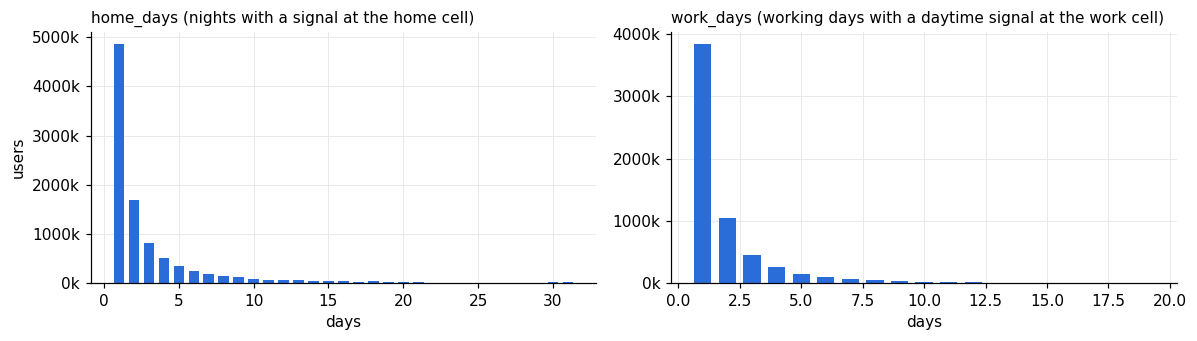

In [5]:
hd = con.execute("SELECT home_days AS d, count(*) AS n FROM panel WHERE home_cell IS NOT NULL GROUP BY 1 ORDER BY 1").df()
wd = con.execute("SELECT work_days AS d, count(*) AS n FROM panel WHERE work_cell IS NOT NULL GROUP BY 1 ORDER BY 1").df()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, d, title in zip(axes, [hd, wd], ["home_days (nights with a signal at the home cell)", "work_days (working days with a daytime signal at the work cell)"]):
    ax.bar(d.d, d.n, color=ACCENT, width=0.7)
    ax.set_title(title, loc="left", fontsize=10); ax.set_xlabel("days")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f}k")
axes[0].set_ylabel("users")
plt.tight_layout(); plt.show()

## 4. City areas and the threshold comparison

Each cell is labelled `city` (Urban Audit city), `metro_other` (inside the Functional Urban Area but outside the city) or `metro`/`outside`.

In [6]:
cells_city  = set(h3.geo_to_cells(CITY, H3_RES))
cells_metro = set(h3.geo_to_cells(METRO, H3_RES))
area_df = pd.DataFrame({"h3_8": sorted(cells_metro),
                        "area": ["city" if c in cells_city else "metro_other" for c in sorted(cells_metro)]})
con.register("area_df", area_df)
con.execute("CREATE OR REPLACE TABLE area_cells AS SELECT * FROM area_df")
print(f"city: {len(cells_city):,} level-{H3_RES} cells; metro: {len(cells_metro):,} cells")

con.execute("""
    CREATE OR REPLACE TABLE panel_area AS
    SELECT p.*, coalesce(ah.area, 'outside') AS home_area, coalesce(aw.area, 'outside') AS work_area
    FROM panel p LEFT JOIN area_cells ah ON p.home_cell = ah.h3_8 LEFT JOIN area_cells aw ON p.work_cell = aw.h3_8
""")

rows = []
for hmin, wmin in THRESHOLDS:
    r = con.execute(f"""
        SELECT count(*) FILTER (WHERE home_days >= {hmin})                                   AS home_ok,
               count(*) FILTER (WHERE home_days >= {hmin} AND work_days >= {wmin})          AS home_and_work_ok,
               count(*) FILTER (WHERE home_days >= {hmin} AND home_area <> 'outside')       AS metro_residents,
               count(*) FILTER (WHERE home_days >= {hmin} AND home_area = 'city')           AS city_residents,
               count(*) FILTER (WHERE home_days >= {hmin} AND work_days >= {wmin} AND work_area <> 'outside') AS metro_workers,
               count(*) FILTER (WHERE home_days >= {hmin} AND work_days >= {wmin} AND work_area = 'city')     AS city_workers,
               count(*) FILTER (WHERE home_days >= {hmin} AND work_days >= {wmin} AND (home_area <> 'outside' OR work_area <> 'outside')) AS metro_commuters
        FROM panel_area""").df().iloc[0]
    rows.append({"home_days >=": hmin, "work_days >=": wmin, **r.to_dict()})
sensitivity = pd.DataFrame(rows)
sensitivity

city: 437 level-8 cells; metro: 7,872 cells


,home_days >=,work_days >=,home_ok,home_and_work_ok,metro_residents,city_residents,metro_workers,city_workers,metro_commuters
0,10,5,662310,322209,20428,9650,9326,4727,9754
1,10,4,662310,387115,20428,9650,11464,5884,12055
2,15,5,334791,206942,9756,4289,5750,2798,5995
3,15,4,334791,232794,9756,4289,6606,3235,6905
4,10,7,662310,209688,20428,9650,5873,2877,6119
5,5,3,1697899,819798,57612,30995,27643,15918,29594


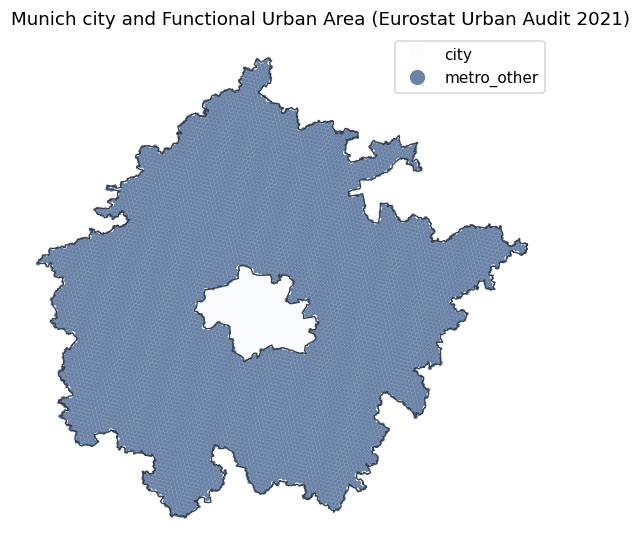

In [7]:
# map of the official polygons with the level-8 cells assigned to each area
fig, ax = plt.subplots(figsize=(7, 6))
gpd.GeoDataFrame(area_df, geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in area_df.h3_8], crs=4326) \
    .plot(column="area", categorical=True, cmap="Blues", linewidth=0, alpha=0.6, ax=ax, legend=True)
for geom in (METRO, CITY):
    gpd.GeoSeries([geom], crs=4326).boundary.plot(ax=ax, color="#374151", linewidth=0.9)
ax.set_title(f"{CITY_NAME} city and Functional Urban Area (Eurostat Urban Audit 2021)", loc="left"); ax.set_axis_off()
plt.show()

## 5. Commuters with the selected thresholds

**Who is counted.** *Residents* are users whose home cell is inside the area (`home_days >= H_MIN`), whether or not a work cell was
found. *Workers* are users whose work cell is inside the area (`work_days >= W_MIN`), wherever they live. *Commuters* are users with
both a home and a work cell.

In [8]:
con.execute(f"""
    CREATE OR REPLACE TABLE commuters AS
    SELECT * FROM panel_area WHERE home_days >= {H_MIN} AND work_days >= {W_MIN}
""")
counts = con.execute(f"""
    SELECT
      count(*) FILTER (WHERE home_days >= {H_MIN} AND home_area <> 'outside')                                     AS "FUA residents",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND home_area <> 'outside' AND work_days >= {W_MIN})            AS "FUA residents with a work cell",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND home_area <> 'outside' AND work_days >= {W_MIN} AND work_area <> 'outside') AS "  ... working inside the FUA",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND home_area <> 'outside' AND work_days >= {W_MIN} AND work_area = 'outside')  AS "  ... working outside the FUA",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND home_area = 'outside' AND work_days >= {W_MIN} AND work_area <> 'outside')  AS "non-residents working in the FUA",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND work_days >= {W_MIN} AND (home_area <> 'outside' OR work_area <> 'outside')) AS "commuters with home or work in the FUA",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND home_area = 'city')                                         AS "city residents",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND home_area = 'city' AND work_days >= {W_MIN})                AS "city residents with a work cell",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND home_area = 'city' AND work_days >= {W_MIN} AND work_area = 'city') AS "  ... working inside the city",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND work_days >= {W_MIN} AND work_area = 'city')                AS "workers in the city (any home)",
      count(*) FILTER (WHERE home_days >= {H_MIN} AND work_days >= {W_MIN})                                       AS "commuters nationally"
    FROM panel_area
""").df().T
counts.columns = [f"users (home_days >= {H_MIN}, work_days >= {W_MIN})"]
counts

,"users (home_days >= 10, work_days >= 4)"
FUA residents,20428
FUA residents with a work cell,10941
... working inside the FUA,10350
... working outside the FUA,591
non-residents working in the FUA,1114
commuters with home or work in the FUA,12055
city residents,9650
city residents with a work cell,4949
... working inside the city,4036
workers in the city (any home),5884


In [9]:
# where do the residents of each area work?
label = {"city": f"{CITY_NAME} city", "metro_other": "commuting zone (FUA outside the city)", "outside": "outside the FUA"}
flows = con.execute("SELECT home_area, work_area, count(*) AS users FROM commuters GROUP BY 1, 2").df()
rows = []
for home in ["city", "metro_other"]:
    f = flows[flows.home_area == home]; total = f.users.sum()
    for work in ["city", "metro_other", "outside"]:
        n = int(f[f.work_area == work].users.sum())
        rows.append({"residents of": label[home], "who work in": label[work], "users": n, "share": f"{100*n/total:.0f}%"})
pd.DataFrame(rows).set_index(["residents of", "who work in"])

users  \
residents of                          who work in                                    
Munich city                           Munich city                             4036   
                                      commuting zone (FUA outside the city)    704   
                                      outside the FUA                          209   
commuting zone (FUA outside the city) Munich city                             1368   
                                      commuting zone (FUA outside the city)   4242   
                                      outside the FUA                          382   

                                                                            share  
residents of                          who work in                                  
Munich city                           Munich city                             82%  
                                      commuting zone (FUA outside the city)   14%  
                                      outside the FUA                          4%  
commuting zone (FUA outside the city) Munich city                             23%  
                                      commuting zone (FUA outside the city)   71%  
                                      outside the FUA                          6%

In [10]:
# where do the people working in each area live?
rows = []
for work in ["city", "metro_other"]:
    f = flows[flows.work_area == work]; total = f.users.sum()
    for home in ["city", "metro_other", "outside"]:
        n = int(f[f.home_area == home].users.sum())
        rows.append({"workers in": label[work], "who live in": label[home], "users": n, "share": f"{100*n/total:.0f}%"})
pd.DataFrame(rows).set_index(["workers in", "who live in"])

users  \
workers in                            who live in                                    
Munich city                           Munich city                             4036   
                                      commuting zone (FUA outside the city)   1368   
                                      outside the FUA                          480   
commuting zone (FUA outside the city) Munich city                              704   
                                      commuting zone (FUA outside the city)   4242   
                                      outside the FUA                          634   

                                                                            share  
workers in                            who live in                                  
Munich city                           Munich city                             69%  
                                      commuting zone (FUA outside the city)   23%  
                                      outside the FUA                          8%  
commuting zone (FUA outside the city) Munich city                             13%  
                                      commuting zone (FUA outside the city)   76%  
                                      outside the FUA                         11%

## 6. Commute distance (home cell centre to work cell centre)

                    count   25%   50%    75%    90%
group                                              
metro <-> outside  1705.0  26.5  54.7  148.1  412.2
within city        4036.0   0.9   2.5    5.5    8.6
within metro       6314.0   0.9   5.8   13.9   22.9


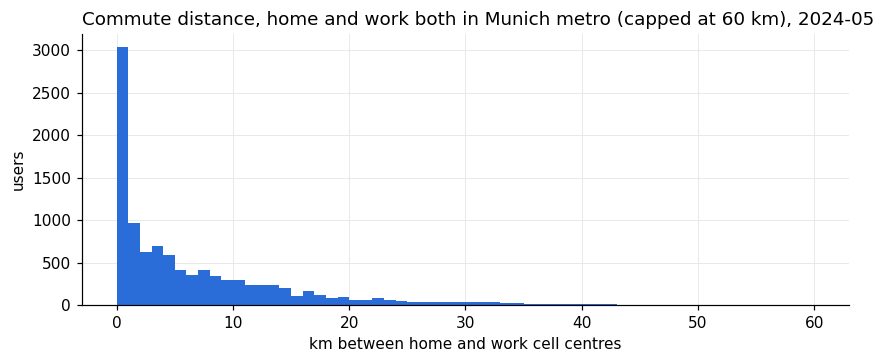

In [11]:
mun = con.execute("""
    SELECT userid, home_cell, work_cell, home_area, work_area, home_days, work_days FROM commuters
    WHERE home_area <> 'outside' OR work_area <> 'outside'
""").df()
cells = pd.unique(np.concatenate([mun.home_cell.values, mun.work_cell.values]))
latlng = pd.DataFrame([h3.cell_to_latlng(c) for c in cells], index=cells, columns=["lat", "lng"])

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

home_ll = latlng.loc[mun.home_cell].values; work_ll = latlng.loc[mun.work_cell].values
mun["dist_km"] = haversine_km(home_ll[:, 0], home_ll[:, 1], work_ll[:, 0], work_ll[:, 1])
mun["group"] = np.select([mun.home_area.eq("city") & mun.work_area.eq("city"),
                          mun.home_area.ne("outside") & mun.work_area.ne("outside")],
                         ["within city", "within metro"], "metro <-> outside")
print(mun.groupby("group").dist_km.describe(percentiles=[.25, .5, .75, .9])[["count", "25%", "50%", "75%", "90%"]].round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 3.2))
d = mun[mun.group != "metro <-> outside"].dist_km.clip(upper=60)
ax.hist(d, bins=np.arange(0, 61, 1), color=ACCENT)
ax.set_title(f"Commute distance, home and work both in {CITY_NAME} metro (capped at 60 km), {MONTH}", loc="left")
ax.set_xlabel("km between home and work cell centres"); ax.set_ylabel("users")
plt.show()

## 7. Where people live and work in the FUA

One map per cell: residents (home cell), workers (work cell), and the net daytime inflow. The thick outline is the city, the thin one the FUA. Then the same maps zoomed to the city.

In [12]:
per_cell = con.execute("""
    SELECT h3_8, sum(residents) AS residents, sum(workers) AS workers FROM (
        SELECT home_cell AS h3_8, count(*) AS residents, 0 AS workers FROM commuters WHERE home_area <> 'outside' GROUP BY 1
        UNION ALL
        SELECT work_cell, 0, count(*) FROM commuters WHERE work_area <> 'outside' GROUP BY 1
    ) GROUP BY 1
""").df()
per_cell["net"] = per_cell.workers - per_cell.residents
per_cell["geometry"] = [Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in per_cell.h3_8]
g = gpd.GeoDataFrame(per_cell, geometry="geometry", crs=4326).to_crs(3857)
city_outline = gpd.GeoSeries([CITY], crs=4326).to_crs(3857)
fua_outline  = gpd.GeoSeries([METRO], crs=4326).to_crs(3857)
vmax = max(g.residents.max(), g.workers.max())

def basemap_image(bounds_3857, zoom, name):
    """Background map as an image file in scratch. Fetched once from Esri World Gray Canvas (no API key needed; CARTO and OSM tiles are blocked for scripts) and reused from disk afterwards."""
    png = SCRATCH / "boundaries" / f"basemap_esri_gray_{CITY_KEY}_{name}_z{zoom}.png"; ext = png.with_suffix(".json")
    if png.exists() and ext.exists():
        return plt.imread(png), json.load(open(ext))
    try:
        import contextily as cx
        minx, miny, maxx, maxy = bounds_3857
        img, extent = cx.bounds2img(minx, miny, maxx, maxy, zoom=zoom, source=cx.providers.Esri.WorldGrayCanvas, ll=False)
        plt.imsave(png, img); json.dump([float(v) for v in extent], open(ext, "w"))
        return img, extent
    except Exception as e:
        print("basemap unavailable, drawing without it:", type(e).__name__, str(e)[:100]); return None, None

def finish_map(ax, title, bounds_3857, zoom, name):
    fua_outline.boundary.plot(ax=ax, color="#374151", linewidth=0.8)
    city_outline.boundary.plot(ax=ax, color="#374151", linewidth=1.2)
    img, extent = basemap_image(bounds_3857, zoom, name)
    if img is not None:
        ax.imshow(img, extent=extent, alpha=0.8, zorder=0, interpolation="bilinear")
    minx, miny, maxx, maxy = bounds_3857
    ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy); ax.set_axis_off()
    ax.set_title(f"{title}, home_days >= {H_MIN}, work_days >= {W_MIN}, {MONTH}", loc="left")
    plt.tight_layout(); plt.show()

FUA_BOUNDS  = fua_outline.total_bounds
CITY_BOUNDS = city_outline.total_bounds + np.array([-2000, -2000, 2000, 2000])

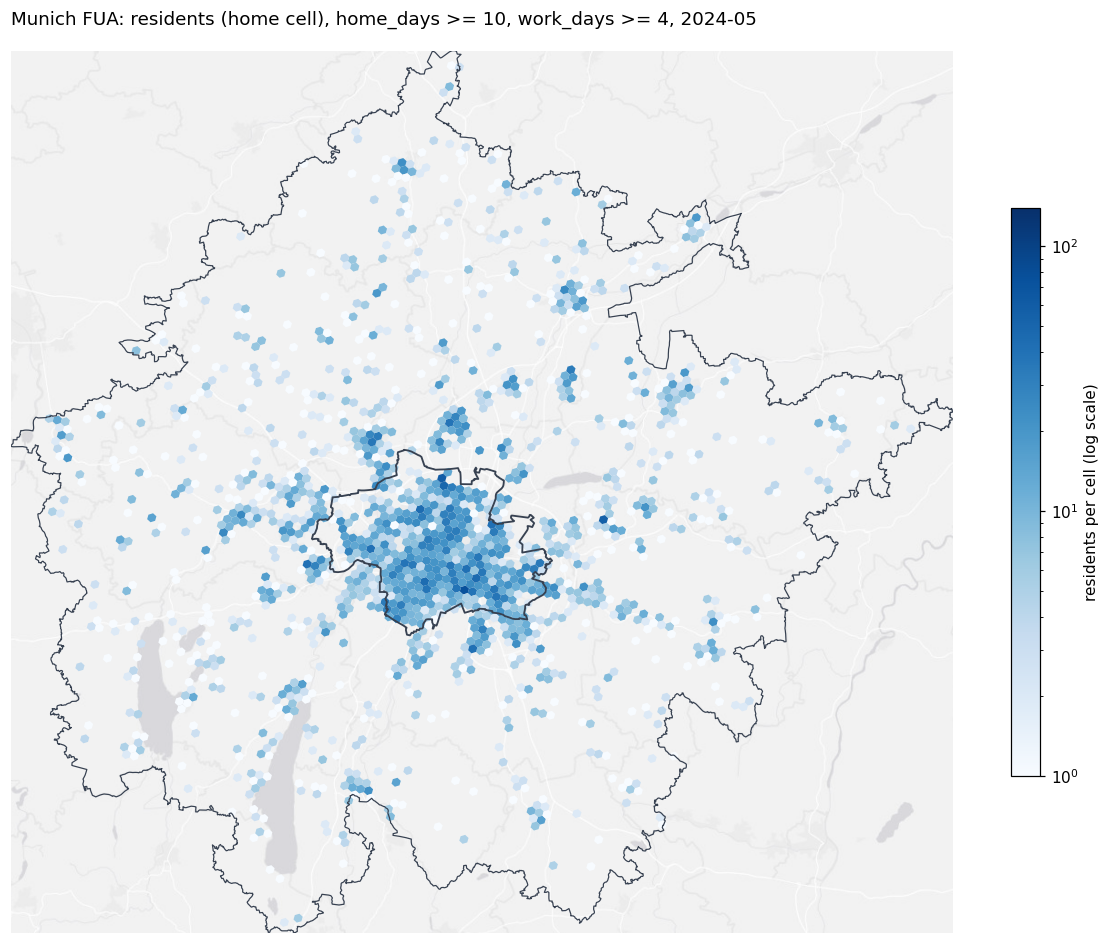

In [13]:
# residents per cell (where the commuters live)
fig, ax = plt.subplots(figsize=(11, 9))
g[g.residents > 0].plot(column="residents", cmap="Blues", norm=LogNorm(vmin=1, vmax=vmax), linewidth=0, ax=ax, legend=True,
                        legend_kwds={"label": "residents per cell (log scale)", "shrink": 0.6})
finish_map(ax, f"{CITY_NAME} FUA: residents (home cell)", FUA_BOUNDS, 10, "fua")

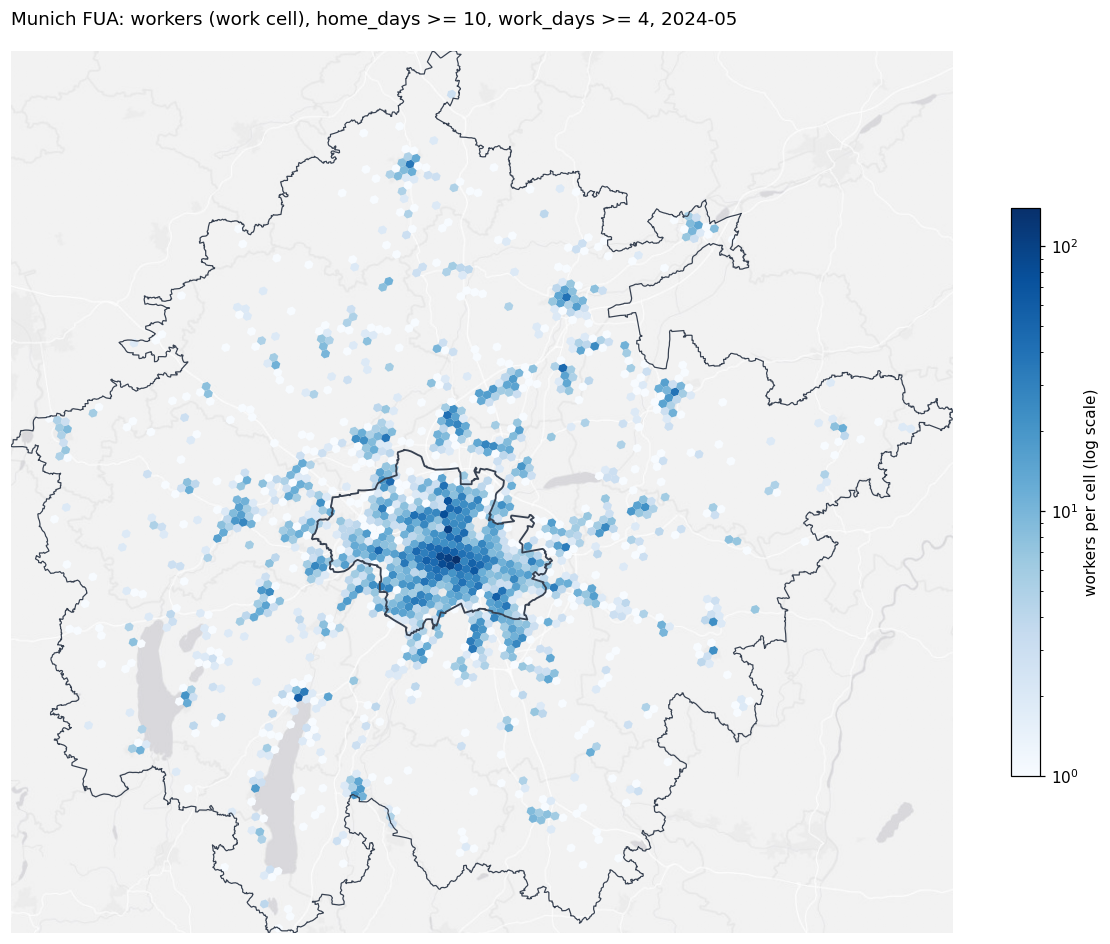

In [14]:
# workers per cell (where the commuters work)
fig, ax = plt.subplots(figsize=(11, 9))
g[g.workers > 0].plot(column="workers", cmap="Blues", norm=LogNorm(vmin=1, vmax=vmax), linewidth=0, ax=ax, legend=True,
                      legend_kwds={"label": "workers per cell (log scale)", "shrink": 0.6})
finish_map(ax, f"{CITY_NAME} FUA: workers (work cell)", FUA_BOUNDS, 10, "fua")

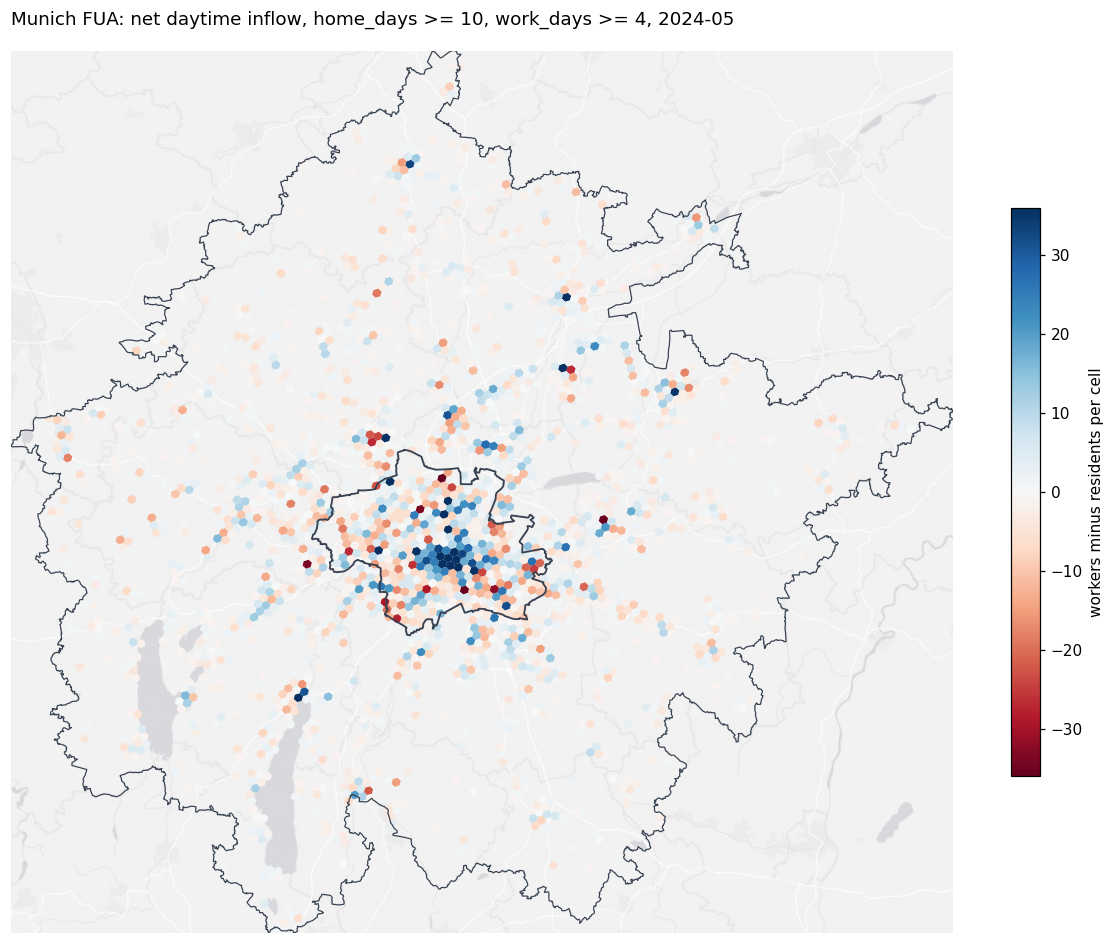

In [15]:
# net daytime inflow: workers minus residents per cell (blue = more workers than residents, red = the opposite)
fig, ax = plt.subplots(figsize=(11, 9))
lim = np.percentile(np.abs(g.net), 99)
g.plot(column="net", cmap="RdBu", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), linewidth=0, ax=ax, legend=True,
       legend_kwds={"label": "workers minus residents per cell", "shrink": 0.6})
finish_map(ax, f"{CITY_NAME} FUA: net daytime inflow", FUA_BOUNDS, 10, "fua")

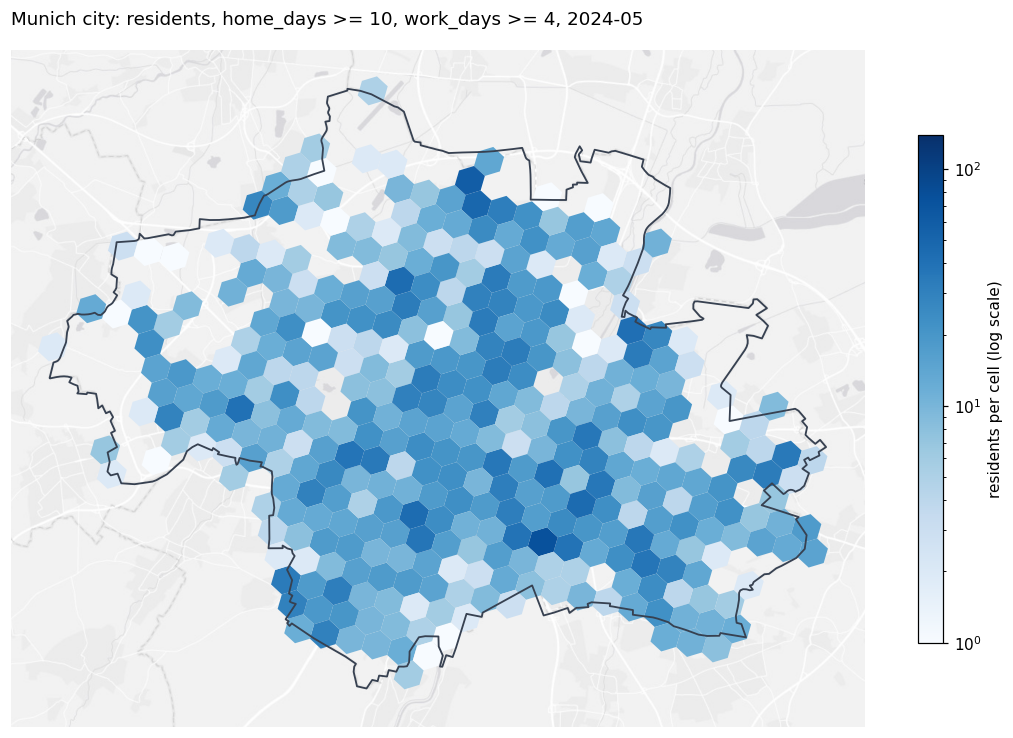

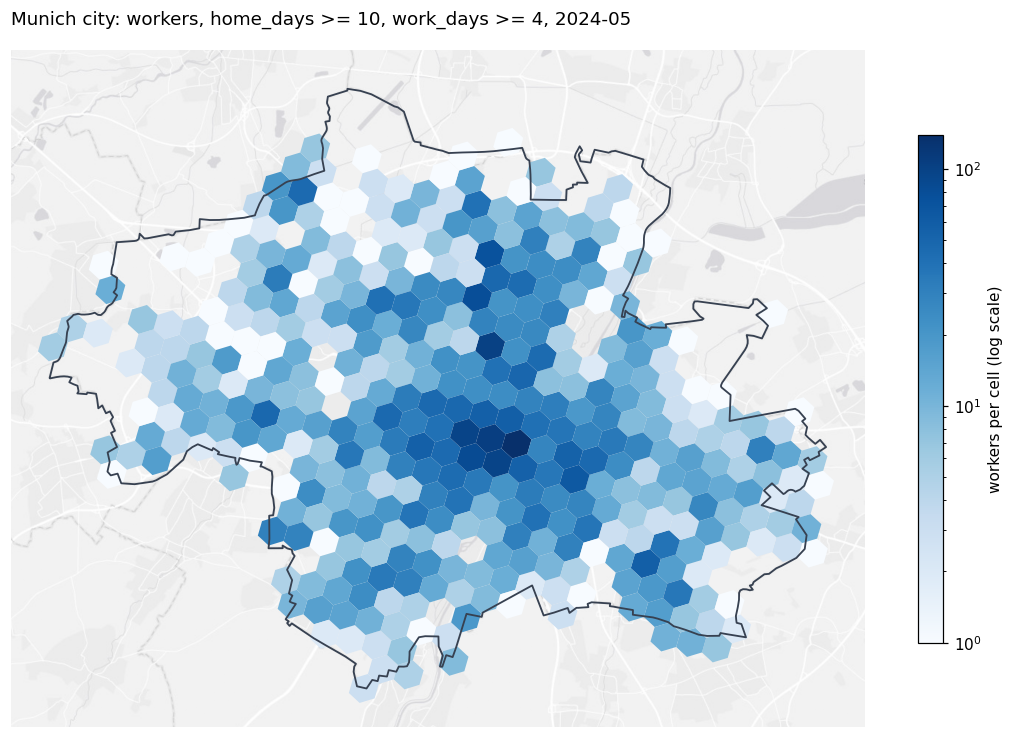

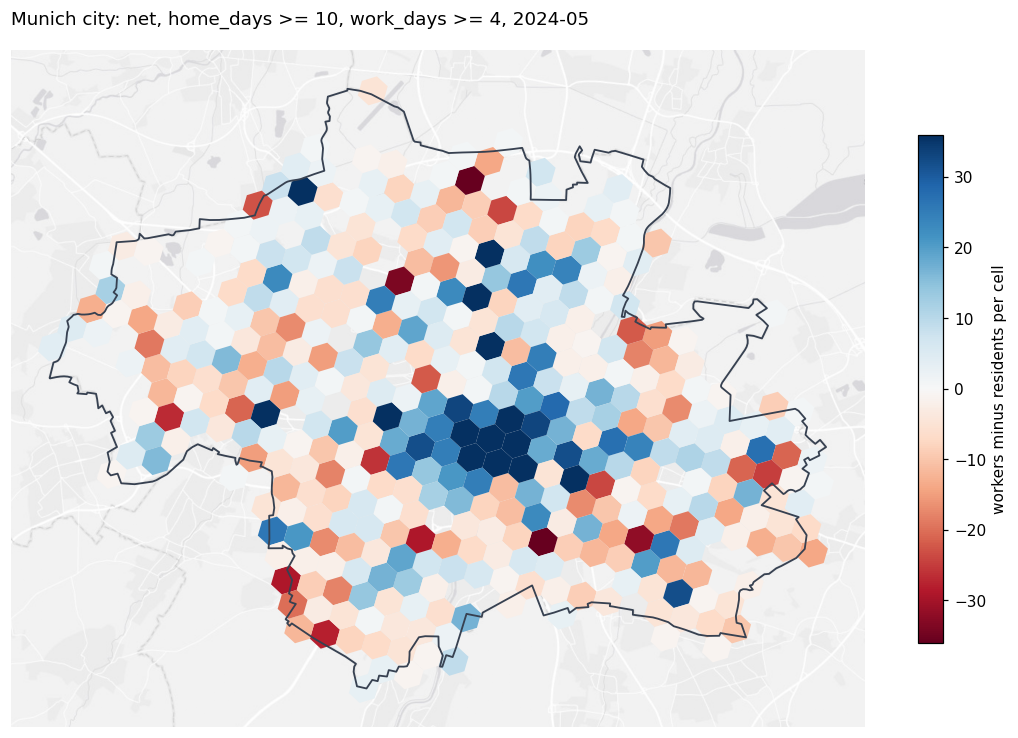

In [16]:
# the same three maps zoomed to the city
for col, cmap, norm, lab in [("residents", "Blues", LogNorm(vmin=1, vmax=vmax), "residents per cell (log scale)"),
                             ("workers",   "Blues", LogNorm(vmin=1, vmax=vmax), "workers per cell (log scale)"),
                             ("net",       "RdBu",  TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), "workers minus residents per cell")]:
    fig, ax = plt.subplots(figsize=(10, 8))
    gc = g[g.intersects(city_outline.iloc[0])]
    gc[gc[col] != 0].plot(column=col, cmap=cmap, norm=norm, linewidth=0, ax=ax, legend=True, legend_kwds={"label": lab, "shrink": 0.6})
    finish_map(ax, f"{CITY_NAME} city: {col}", CITY_BOUNDS, 12, "city")

In [17]:
# busiest work cells (sanity check: city centre, Garching, airport, BMW/Milbertshofen, ...)
busiest = per_cell.nlargest(12, "workers").copy()
busiest["lat"], busiest["lon"] = zip(*[h3.cell_to_latlng(c) for c in busiest.h3_8])
busiest[["h3_8", "workers", "residents", "lat", "lon"]].reset_index(drop=True)

,h3_8,workers,residents,lat,lon
0,881f8d7a49fffff,140.0,3.0,48.137697,11.578686
1,881f8d44a7fffff,106.0,9.0,48.139390,11.566674
2,881f8d448dfffff,102.0,29.0,48.168131,11.566412
3,881f8d7a4dfffff,97.0,36.0,48.131780,11.569742
4,881f8d44a5fffff,96.0,13.0,48.141081,11.554662
5,881f8d459bfffff,84.0,20.0,48.133471,11.557732
6,881f8d44c1fffff,79.0,30.0,48.183342,11.560272
7,881f8d46b5fffff,73.0,3.0,48.196861,11.566150
8,881f8d7a55fffff,64.0,7.0,48.126697,11.605775
9,881f8d7aedfffff,57.0,37.0,48.100456,11.638982


## 8. Why do residents have no work cell?

Every FUA resident with `home_days >= H_MIN` is put into exactly one group, checked in this order:

1. **has a work cell inside the FUA** / **2. outside the FUA** (`work_days >= W_MIN`)
3. **scattered**: daytime signals away from home on at least `W_MIN` working days, but no single non-home cell reaches `W_MIN` days
4. **daytime only at home**: daytime signals on at least `W_MIN` working days, but away from the home cell on fewer than `W_MIN` days
5. **no daytime signals**: seen on at least `W_MIN` working days, but with fewer than `W_MIN` days of 09:00–17:00 signals
6. **too few working days**: seen on fewer than `W_MIN` working days at all

The columns answer the usual suspects: are these users tracked less (signals per day), are they never away from home (days away),
or are they away but outside the FUA (share of away days outside the FUA).

In [18]:
# per user: working days with a daytime signal away from the home cell, inside the FUA, and the spread over non-home cells
con.execute(f"""
    CREATE OR REPLACE TABLE daytime_days AS
    SELECT u.userid,
           count(DISTINCT u.day) FILTER (WHERE u.h3_8 <> h.home_cell)                          AS days_away_from_home,
           count(DISTINCT u.day) FILTER (WHERE u.h3_8 <> h.home_cell AND a.h3_8 IS NOT NULL)   AS days_away_in_metro
    FROM (SELECT userid, day, h3_8, ({WORK}) AS n_work FROM ud WHERE {WORKDAY_FILTER}) u
    JOIN home h USING (userid) LEFT JOIN area_cells a ON u.h3_8 = a.h3_8
    WHERE u.n_work > 0 GROUP BY u.userid
""")
con.execute(f"""
    CREATE OR REPLACE TABLE away_cells AS
    SELECT userid, count(*) AS n_away_cells, max(days_in_cell) AS max_days_one_cell FROM (
        SELECT u.userid, u.h3_8, count(DISTINCT u.day) AS days_in_cell
        FROM (SELECT userid, day, h3_8, ({WORK}) AS n_work FROM ud WHERE {WORKDAY_FILTER}) u
        JOIN home h USING (userid)
        WHERE u.h3_8 <> h.home_cell AND u.n_work > 0 GROUP BY u.userid, u.h3_8
    ) GROUP BY userid
""")
con.execute("""
    CREATE OR REPLACE TABLE residents AS
    SELECT p.*, coalesce(t.days_away_from_home, 0) AS days_away_from_home, coalesce(t.days_away_in_metro, 0) AS days_away_in_metro,
           coalesce(c.n_away_cells, 0) AS n_away_cells, coalesce(c.max_days_one_cell, 0) AS max_days_one_cell
    FROM panel_area p LEFT JOIN daytime_days t USING (userid) LEFT JOIN away_cells c USING (userid)
    WHERE p.home_area <> 'outside'
""")
print("residents table ready")

residents table ready


In [19]:
reasons = con.execute(f"""
    WITH r AS (
        SELECT *,
               CASE WHEN work_days >= {W_MIN} AND work_area <> 'outside'  THEN '1 has work cell in FUA'
                    WHEN work_days >= {W_MIN}                             THEN '2 has work cell outside FUA'
                    WHEN days_away_from_home >= {W_MIN}                   THEN '3 away from home, but scattered over cells'
                    WHEN workdays_with_daytime_signal >= {W_MIN}          THEN '4 daytime signals only at the home cell'
                    WHEN workdays_observed >= {W_MIN}                     THEN '5 no 09-17 signals on enough working days'
                    ELSE                                                       '6 seen on too few working days' END AS reason
        FROM residents WHERE home_days >= {H_MIN}
    )
    SELECT reason,
           count(*)                                                AS users,
           round(100.0 * count(*) / sum(count(*)) OVER (), 1)      AS pct_of_residents,
           round(median(n_signals * 1.0 / days_observed))          AS signals_per_day_median,
           median(days_away_from_home)                             AS days_away_from_home_median,
           round(100.0 * sum(days_away_from_home - days_away_in_metro) / nullif(sum(days_away_from_home), 0), 1) AS pct_away_days_outside_fua
    FROM r GROUP BY reason ORDER BY reason
""").df()
reasons.set_index("reason")

,users,pct_of_residents,signals_per_day_median,days_away_from_home_median,pct_away_days_outside_fua
reason,,,,,
1 has work cell in FUA,10350,50.7,50.0,9.0,1.9
2 has work cell outside FUA,591,2.9,50.0,10.0,47.7
"3 away from home, but scattered over cells",5343,26.2,43.0,6.0,7.3
4 daytime signals only at the home cell,4015,19.7,36.0,2.0,7.6
5 no 09-17 signals on enough working days,129,0.6,28.0,1.0,7.6


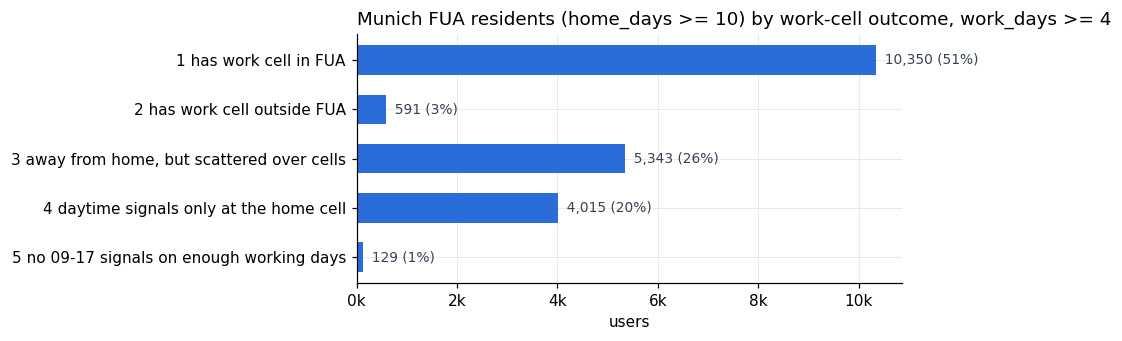

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(reasons.reason[::-1], reasons.users[::-1], color=ACCENT, height=0.6)
for y, (n, p) in enumerate(zip(reasons.users[::-1], reasons.pct_of_residents[::-1])):
    ax.text(n, y, f"  {int(n):,} ({p:.0f}%)", va="center", fontsize=9, color="#374151")
ax.set_title(f"{CITY_NAME} FUA residents (home_days >= {H_MIN}) by work-cell outcome, work_days >= {W_MIN}", loc="left")
ax.set_xlabel("users"); ax.xaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f}k")
plt.tight_layout(); plt.show()

### A closer look at the two big groups

- **Scattered**: how close are they to qualifying? `max_days_one_cell` is the most working days any single non-home cell has. Users
  with `max_days_one_cell >= W_MIN` but no work cell exist because the work cell is the cell with the most *signals*, which is not always
  the cell with the most *days*.
- **Daytime only at home**: are they simply tracked less, or genuinely at home? Compare signals per day with the workers.

In [21]:
# scattered users: how many working days does their best non-home cell reach? (W_MIN would be enough for a work cell)
con.execute(f"""
    SELECT max_days_one_cell AS best_cell_days, count(*) AS users, round(avg(n_away_cells)) AS different_cells_avg
    FROM residents
    WHERE home_days >= {H_MIN} AND (work_days IS NULL OR work_days < {W_MIN}) AND days_away_from_home >= {W_MIN}
    GROUP BY 1 ORDER BY 1
""").df().set_index("best_cell_days")

,users,different_cells_avg
best_cell_days,,
1,256,13.0
2,1495,19.0
3,2171,23.0
4,700,38.0
5,380,50.0
6,182,56.0
7,80,50.0
8,40,52.0
9,18,100.0


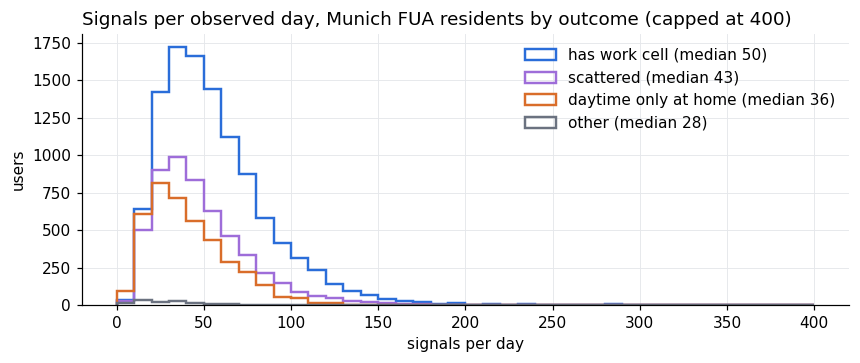

In [22]:
cmp = con.execute(f"""
    SELECT CASE WHEN work_days >= {W_MIN} THEN 'has work cell'
                WHEN days_away_from_home >= {W_MIN} THEN 'scattered'
                WHEN workdays_with_daytime_signal >= {W_MIN} THEN 'daytime only at home' ELSE 'other' END AS grp,
           n_signals * 1.0 / days_observed AS signals_per_day
    FROM residents WHERE home_days >= {H_MIN}
""").df()
order = ["has work cell", "scattered", "daytime only at home", "other"]
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, g in enumerate(order):
    v = cmp[cmp.grp == g].signals_per_day.clip(upper=400)
    ax.hist(v, bins=np.arange(0, 401, 10), histtype="step", linewidth=1.6, label=f"{g} (median {v.median():.0f})",
            color=[ACCENT, "#9E6DD9", "#D96D2A", "#6b7280"][i])
ax.set_title(f"Signals per observed day, {CITY_NAME} FUA residents by outcome (capped at 400)", loc="left")
ax.set_xlabel("signals per day"); ax.set_ylabel("users"); ax.legend(frameon=False)
plt.show()

## 10. Commuting flows: from where to where

Three views of the home-to-work links. The tables count all commuters with home or work inside the FUA; **the maps only show commuters with both home and work inside the FUA**.

1. **Between districts** (Eurostat NUTS3 regions, e.g. for Munich: the city, Landkreis München, Dachau, Freising, ...): a table of the
   strongest district-to-district flows and a map with one arrow per flow. Readable names, comparable to official commuter statistics.
2. **Between H3 level-7 cells** (about 5 km² each) across the whole FUA: arrows from the home cell to the work cell, width proportional
   to the number of users, for links with at least `MIN_FLOW_H3` users.
3. The same, zoomed to the city.

Arrows point from home to work. Users whose home and work fall in the same unit are shown as circles (district map) or left out (cell maps).

In [23]:
MIN_FLOW_NUTS = 20    # smallest district-to-district flow drawn on the district map
MIN_FLOW_H3   = 3     # smallest cell-to-cell flow drawn on the H3 level-7 maps

# ---- districts: Eurostat NUTS 2021 level 3 (downloaded on first run) ----
NUTS_URL = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/"
def nuts3_layer():
    f = SCRATCH / "boundaries" / "NUTS_RG_01M_2021_4326_LEVL_3.geojson"
    if not f.exists():
        urllib.request.urlretrieve(NUTS_URL + f.name, f)
    n = gpd.read_file(f)
    n = n[n.CNTR_CODE == "DE"][["NUTS_ID", "NAME_LATN", "geometry"]].copy()
    n["name"] = n.NAME_LATN.str.replace(", Kreisfreie Stadt", " (Stadt)").str.replace(", Landkreis", " (Landkreis)")
    return n
nuts = nuts3_layer()

# commuters with home or work in the FUA, with the centre of their home and work cells
links = con.execute("""
    SELECT userid, home_cell, work_cell, home_area, work_area FROM commuters
    WHERE home_area <> 'outside' OR work_area <> 'outside'
""").df()
cells8 = pd.unique(np.concatenate([links.home_cell.values, links.work_cell.values]))
ll = {c: h3.cell_to_latlng(c) for c in cells8}
pts = gpd.GeoDataFrame({"h3_8": cells8}, geometry=gpd.points_from_xy([ll[c][1] for c in cells8], [ll[c][0] for c in cells8]), crs=4326)
cell_district = (gpd.sjoin_nearest(pts.to_crs(3857), nuts[["name", "geometry"]].to_crs(3857), how="left")
                   .drop_duplicates("h3_8").set_index("h3_8")["name"])   # nearest district, so cells on a boundary still get a name
links["home_district"] = cell_district.reindex(links.home_cell).values
links["work_district"] = cell_district.reindex(links.work_cell).values
links["home7"] = [h3.cell_to_parent(c, 7) for c in links.home_cell]
links["work7"] = [h3.cell_to_parent(c, 7) for c in links.work_cell]
links_in = links[(links.home_area != "outside") & (links.work_area != "outside")]   # for the MAPS: home AND work inside the FUA
print(f"{len(links):,} commuters with home or work in the FUA; {len(links_in):,} with both inside (used for the maps)")

od_district = (links.groupby(["home_district", "work_district"]).size().rename("users").reset_index()
                    .sort_values("users", ascending=False))
between = od_district[od_district.home_district != od_district.work_district]
within  = od_district[od_district.home_district == od_district.work_district]
print(f"{len(links):,} commuters, {len(between):,} district pairs, {len(within):,} districts with internal commuters")
print("\nStrongest flows between districts (home -> work):")
between.head(20).reset_index(drop=True)

12,055 commuters with home or work in the FUA; 10,350 with both inside (used for the maps)
12,055 commuters, 692 district pairs, 16 districts with internal commuters

Strongest flows between districts (home -> work):


,home_district,work_district,users
0,München (Landkreis),München (Stadt),534
1,München (Stadt),München (Landkreis),455
2,Fürstenfeldbruck,München (Stadt),214
3,Dachau,München (Stadt),192
4,Ebersberg,München (Stadt),130
5,Ebersberg,München (Landkreis),103
6,Freising,München (Stadt),94
7,Starnberg,München (Stadt),75
8,München (Stadt),Fürstenfeldbruck,62
9,Erding,München (Stadt),56


In [24]:
# commuters who live and work in the same district
within.sort_values("users", ascending=False).reset_index(drop=True).rename(columns={"home_district": "district"}).drop(columns="work_district").head(12)

,district,users
0,München (Stadt),4048
1,München (Landkreis),923
2,Fürstenfeldbruck,515
3,Freising,461
4,Dachau,358
5,Starnberg,326
6,Ebersberg,293
7,Erding,268
8,Pfaffenhofen a. d. Ilm,146
9,Bad Tölz-Wolfratshausen,138


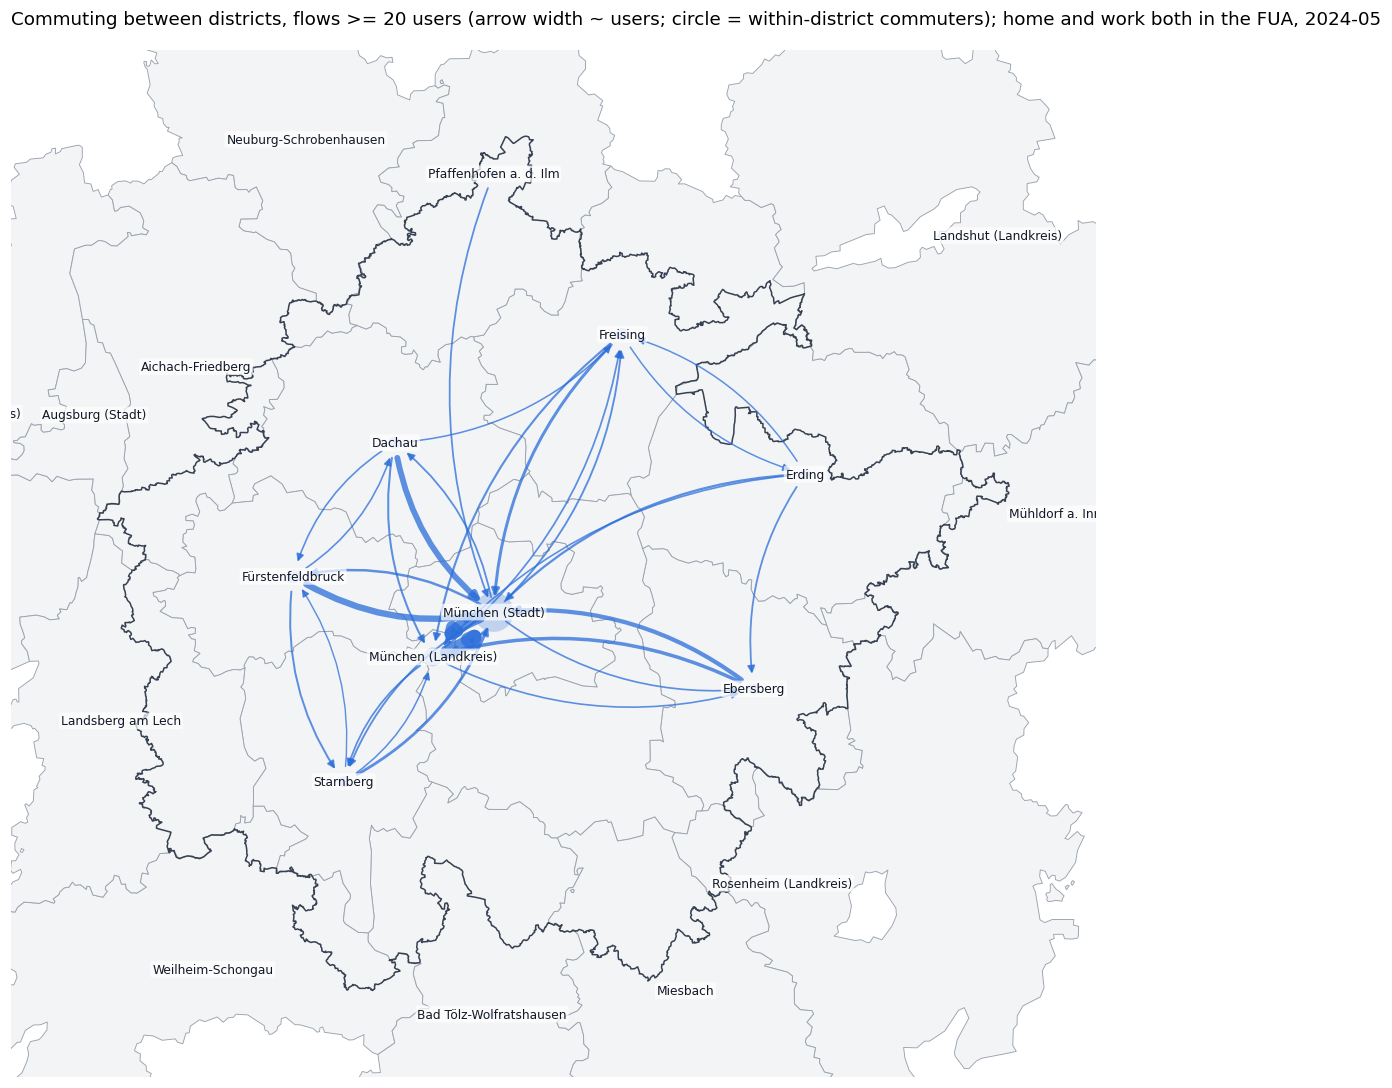

In [25]:
# district map: circles = commuters within the district, arrows = flows between districts (width ~ users).
# Only districts that overlap the FUA are drawn; flows to or from other districts are in the table above but not on the map.
od_in = links_in.groupby(["home_district", "work_district"]).size().rename("users").reset_index()
between_in, within_in = od_in[od_in.home_district != od_in.work_district], od_in[od_in.home_district == od_in.work_district]
regs = nuts[nuts.intersects(METRO)].to_crs(3857)
on_map = set(regs.name)
cent = regs.set_index("name").geometry.representative_point()

fig, ax = plt.subplots(figsize=(12, 10))
regs.plot(ax=ax, facecolor="#f3f4f6", edgecolor="#9ca3af", linewidth=0.6)
fua_outline.boundary.plot(ax=ax, color="#374151", linewidth=1.0)
internal = within_in[within_in.home_district.isin(on_map)].set_index("home_district").users
ax.scatter([cent[n].x for n in internal.index], [cent[n].y for n in internal.index], s=internal.values / 6,
           color=ACCENT, alpha=0.25, linewidth=0, zorder=2)
drawn = between_in[(between_in.users >= MIN_FLOW_NUTS) & between_in.home_district.isin(on_map) & between_in.work_district.isin(on_map)]
for _, r in drawn.iterrows():
    p0, p1 = cent[r.home_district], cent[r.work_district]
    ax.annotate("", xy=(p1.x, p1.y), xytext=(p0.x, p0.y), zorder=3, annotation_clip=True,
                arrowprops=dict(arrowstyle="-|>", color=ACCENT, alpha=0.75, lw=0.6 + r.users / 60,
                                shrinkA=10, shrinkB=10, connectionstyle="arc3,rad=0.2"))
for n in on_map:
    ax.text(cent[n].x, cent[n].y, n, fontsize=8, ha="center", va="center", color="#111827", zorder=4, clip_on=True,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
minx, miny, maxx, maxy = fua_outline.total_bounds
ax.set_xlim(minx - 15000, maxx + 15000); ax.set_ylim(miny - 15000, maxy + 15000); ax.set_axis_off()
ax.set_title(f"Commuting between districts, flows >= {MIN_FLOW_NUTS} users (arrow width ~ users; circle = within-district commuters); home and work both in the FUA, {MONTH}", loc="left")
plt.tight_layout(); plt.show()

1,011 links with >= 3 users, covering 5,203 of 8,388 commuters between different level-7 cells (home and work in the FUA)


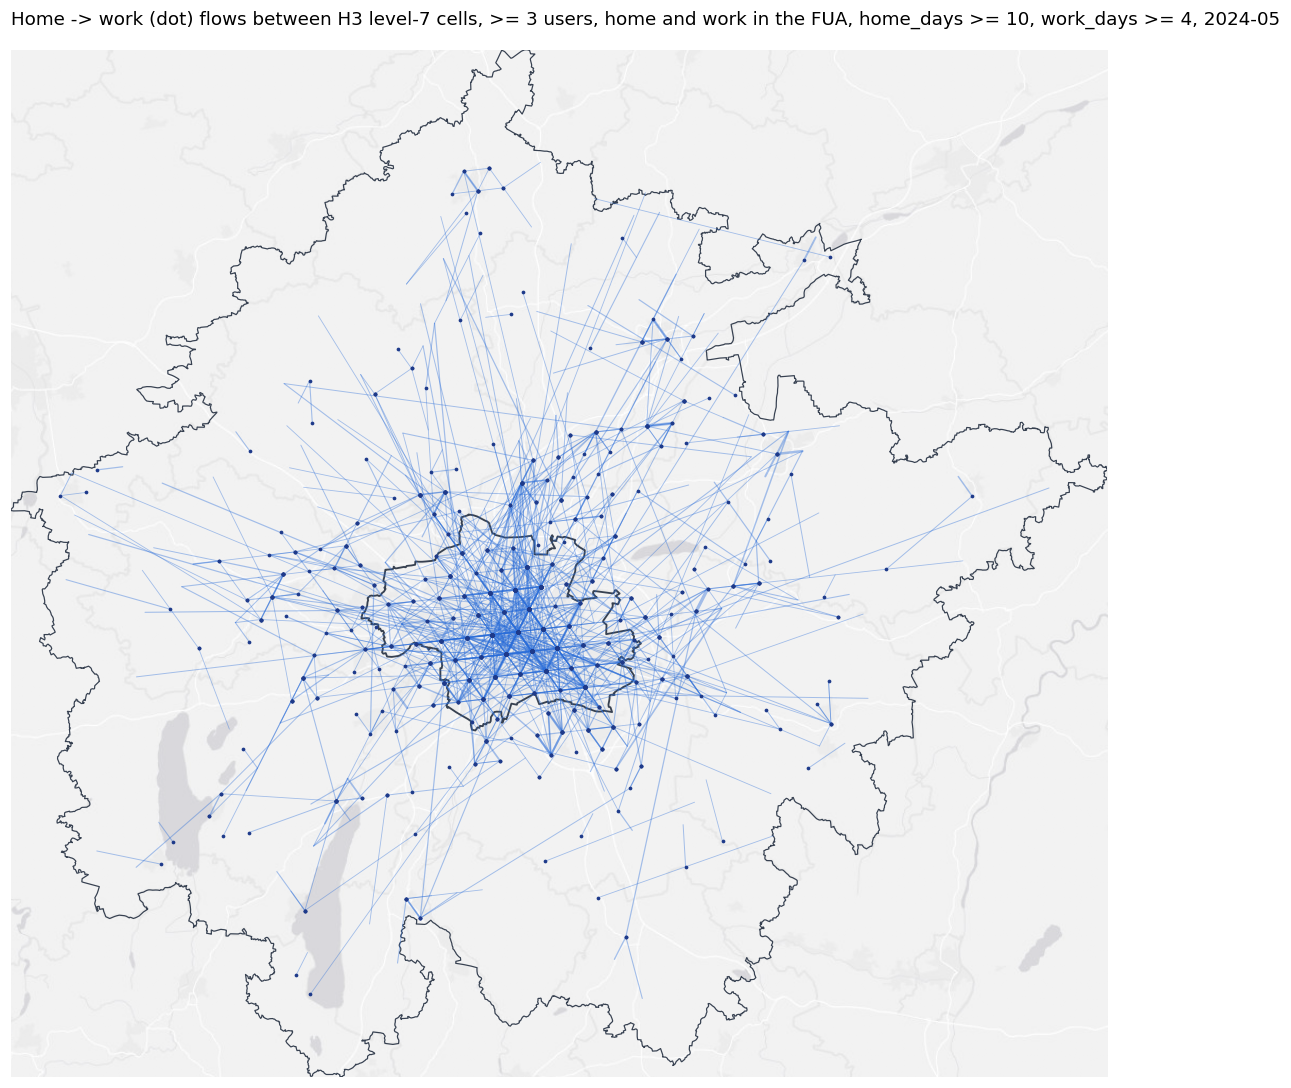

In [26]:
# H3 level-7 flows over the whole FUA: a line from the home cell to a dot at the work cell, width ~ users
od7 = links.groupby(["home7", "work7"]).size().rename("users").reset_index()          # all commuters (for the table below)
od7 = od7[od7.home7 != od7.work7]
od7_in = links_in.groupby(["home7", "work7"]).size().rename("users").reset_index()    # home and work both in the FUA (for the maps)
od7_in = od7_in[od7_in.home7 != od7_in.work7]
c7 = pd.unique(np.concatenate([od7.home7.values, od7.work7.values]))
p7 = gpd.GeoSeries(gpd.points_from_xy([h3.cell_to_latlng(c)[1] for c in c7], [h3.cell_to_latlng(c)[0] for c in c7]), index=c7, crs=4326).to_crs(3857)
district7 = (gpd.sjoin_nearest(gpd.GeoDataFrame({"h3_7": c7}, geometry=p7.values, crs=3857), nuts[["name", "geometry"]].to_crs(3857), how="left")
               .drop_duplicates("h3_7").set_index("h3_7")["name"])

def flow_map(sel, bounds, zoom, name, title):
    """Lines are clipped to the map, so links to places far outside (e.g. a home in another region) do not stretch the figure."""
    fig, ax = plt.subplots(figsize=(12, 10))
    sel = sel.sort_values("users")
    for _, r in sel.iterrows():
        p0, p1 = p7[r.home7], p7[r.work7]
        ax.plot([p0.x, p1.x], [p0.y, p1.y], color=ACCENT, alpha=0.4, lw=0.3 + min(r.users, 60) / 12, solid_capstyle="round", zorder=3)
    ax.scatter([p7[c].x for c in sel.work7], [p7[c].y for c in sel.work7], s=6, color="#1e3a8a", zorder=4, linewidth=0)
    finish_map(ax, title, bounds, zoom, name)

sel = od7_in[od7_in.users >= MIN_FLOW_H3]
print(f"{len(sel):,} links with >= {MIN_FLOW_H3} users, covering {sel.users.sum():,} of {od7_in.users.sum():,} commuters between different level-7 cells (home and work in the FUA)")
flow_map(sel, FUA_BOUNDS, 10, "fua", f"Home -> work (dot) flows between H3 level-7 cells, >= {MIN_FLOW_H3} users, home and work in the FUA")

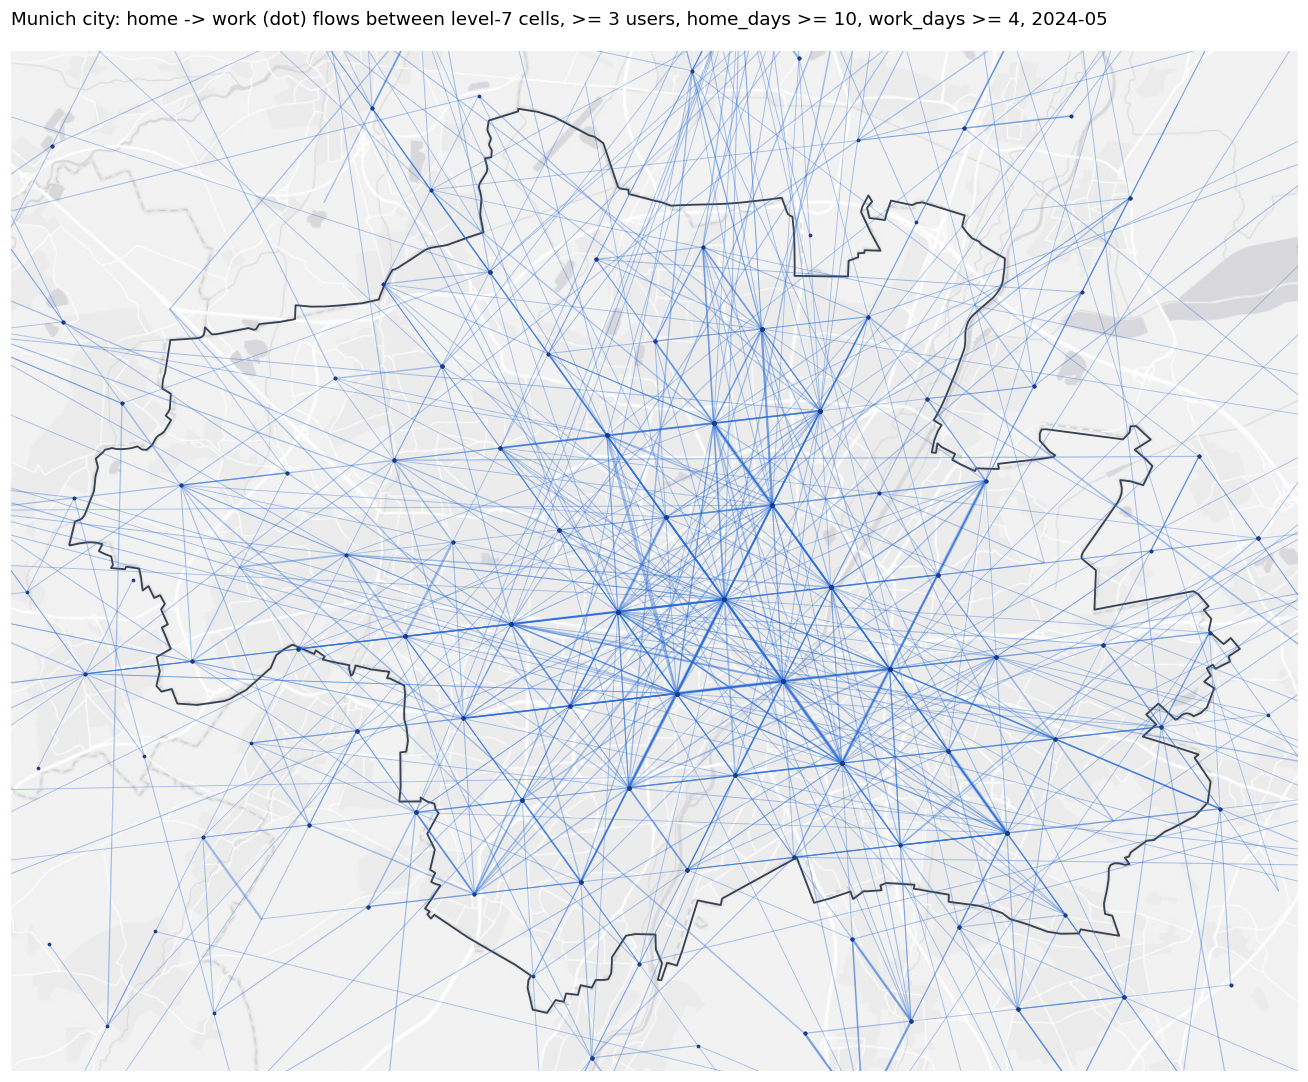

In [27]:
# zoom to the city: links with at least one end inside the city bounds (the other end may be off the map)
minx, miny, maxx, maxy = CITY_BOUNDS
inside = lambda p: (minx <= p.x <= maxx) and (miny <= p.y <= maxy)
sel_city = sel[[inside(p7[a]) or inside(p7[b]) for a, b in zip(sel.home7, sel.work7)]]
flow_map(sel_city, CITY_BOUNDS, 12, "city", f"{CITY_NAME} city: home -> work (dot) flows between level-7 cells, >= {MIN_FLOW_H3} users")

In [28]:
# strongest cell-to-cell links, with coordinates of both ends (home -> work)
strongest = od7.sort_values("users", ascending=False).head(15).copy()
strongest["home_lat"], strongest["home_lon"] = zip(*[h3.cell_to_latlng(c) for c in strongest.home7])
strongest["work_lat"], strongest["work_lon"] = zip(*[h3.cell_to_latlng(c) for c in strongest.work7])
strongest["home_district"] = district7.reindex(strongest.home7).values
strongest["work_district"] = district7.reindex(strongest.work7).values
strongest[["users", "home_district", "home_lat", "home_lon", "work_district", "work_lat", "work_lon"]].reset_index(drop=True)

,users,home_district,home_lat,home_lon,work_district,work_lat,work_lon
0,26,München (Stadt),48.183342,11.560272,München (Stadt),48.166440,11.578429
1,25,München (Stadt),48.113168,11.599894,München (Stadt),48.130087,11.581753
2,25,München (Stadt),48.115687,11.632859,München (Stadt),48.098754,11.650989
3,24,München (Stadt),48.108101,11.533985,München (Stadt),48.127552,11.548791
4,24,München (Stadt),48.171486,11.644405,München (Stadt),48.152052,11.629559
5,22,München (Stadt),48.127552,11.548791,München (Stadt),48.146999,11.563605
6,22,München (Stadt),48.113168,11.599894,München (Stadt),48.132612,11.614722
7,22,Ebersberg,48.183942,11.809466,Ebersberg,48.164525,11.794565
8,22,München (Stadt),48.130087,11.581753,München (Stadt),48.127552,11.548791
9,20,München (Stadt),48.180799,11.527290,München (Stadt),48.127552,11.548791


In [29]:
# save the summary tables of this city for compare_cities.ipynb
counts.to_csv(RESULTS_DIR / "counts.csv")
sensitivity.to_csv(RESULTS_DIR / "thresholds.csv", index=False)
reasons.to_csv(RESULTS_DIR / "reasons.csv", index=False)
mun.groupby("group").dist_km.describe(percentiles=[.25, .5, .75, .9]).to_csv(RESULTS_DIR / "distance.csv")
between.head(30).to_csv(RESULTS_DIR / "district_flows.csv", index=False)
within.to_csv(RESULTS_DIR / "district_internal.csv", index=False)
pd.DataFrame(rows_res := [dict(city=CITY_NAME, city_key=CITY_KEY, month=MONTH, H_MIN=H_MIN, W_MIN=W_MIN,
                               fua_km2=round(gpd.GeoSeries([METRO], crs=4326).to_crs(3035).area.iloc[0] / 1e6),
                               city_km2=round(gpd.GeoSeries([CITY], crs=4326).to_crs(3035).area.iloc[0] / 1e6))]).to_csv(RESULTS_DIR / "meta.csv", index=False)
print("saved to", RESULTS_DIR)

saved to /scratch/project_2022768/marinflo/locomizer/results/munich_2024-05


## Notes for the next steps

- **Validation against Locomizer's own panels**: `parametric_score/<month>/LocoResidents` and `LocoWorkers_2` give a home / work cell
  (H3-10) per user. Comparing them with `home_cell` / `work_cell` here would show how far the simple rule is from the vendor's model.
  Note that `userid` there is an int64 hash, not the string used in the signals.
- **Night window across midnight**: night hours 0–6 belong to the calendar day they fall in, not to the previous evening.
- **Loose support**: `work_days` counts working days with at least one daytime signal at the work cell. A regularly visited
  non-work place (gym, school run, supermarket) can qualify; the `daytime_at_home_days` column and the concentration chart help
  to judge how often that happens.